##Run quadrupolar relaxation in one line, with input params (namely path to EFG data file) in `dynpy_qrax_params.py` under `class Quadrupolar`

In [9]:
%run -m dynpy -- --Qrelax dynpy_qrax_params.py

Results written to ./I-ADF-efg-I-relax.csv


##Below: Run in manual steps to see/work with intermediate data such as autocorrelation functions (acfs)

In [1]:
from qrax import *
import matplotlib

In [2]:
cart = read_efg_data("./I-ADF-efg.csv")

In [3]:
cart.head()

,system,traj,frame,time,label,symbol,Vxx,Vxy,Vxz,Vyx,Vyy,Vyz,Vzx,Vzy,Vzz,V11,V22,V33,Eta,ComputeTime
0,I-ADF,1,42000,6.09,1,H,0.239847,-0.174043,0.017258,-0.174043,-0.069290,0.013889,0.017258,0.013889,-0.170557,-0.136216,-0.182041,0.318257,0.14399,2813.0
1,I-ADF,1,42000,6.09,2,H,0.027386,0.261191,0.158340,0.261191,0.111356,0.204175,0.158340,0.204175,-0.138742,-0.193204,-0.254373,0.447578,0.13667,2813.0
2,I-ADF,1,42000,6.09,3,H,-0.069592,0.357247,0.190816,0.357247,0.283002,0.302543,0.190816,0.302543,-0.213410,-0.291608,-0.361177,0.652786,0.10657,2813.0
3,I-ADF,1,42000,6.09,4,H,0.259474,-0.128789,0.066652,-0.128789,-0.095883,-0.006028,0.066652,-0.006028,-0.163591,-0.132302,-0.177936,0.310238,0.14709,2813.0
4,I-ADF,1,42000,6.09,5,H,0.218572,-0.099655,-0.173108,-0.099655,-0.115821,0.028685,-0.173108,0.028685,-0.102751,-0.136045,-0.182402,0.318446,0.14557,2813.0


In [4]:
spatial = cart_to_spatial(cart,pass_columns=['traj','system'])

In [5]:
acfs = spatial.groupby('label',group_keys=True)[spatial.columns].apply(correlate, pass_columns=['traj','system','symbol','frame','time'])

In [6]:
acfs.head()

$f_{2,-2}$  $f_{2,-1}$  $f_{2,0}$  $f_{2,1}$  $f_{2,2}$  frame  \
label                                                                       
1     0      0.054734    0.051704   0.049849   0.051704   0.054734  42000   
      91     0.036871    0.034669   0.034157   0.034669   0.036871  42200   
      182    0.028991    0.029630   0.031276   0.029630   0.028991  42400   
      273    0.028127    0.027375   0.028582   0.027375   0.028127  42600   
      364    0.026738    0.027769   0.027922   0.027769   0.026738  42800   

            time  label  traj system symbol  
label                                        
1     0    6.090    1.0     1  I-ADF      H  
      91   6.119    1.0     1  I-ADF      H  
      182  6.148    1.0     1  I-ADF      H  
      273  6.177    1.0     1  I-ADF      H  
      364  6.206    1.0     1  I-ADF      H

In [7]:
I_acfs = acfs[acfs['symbol']=='I'].sort_values(by='frame')

Matplotlib is building the font cache; this may take a moment.


<Axes: xlabel='time'>

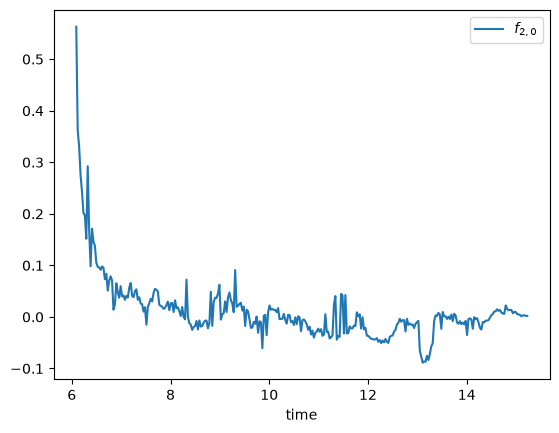

In [8]:
I_acfs.plot(x='time',y='$f_{2,0}$')

In [9]:
g = spectral_dens(I_acfs, cutoff=False, cutoff_tol=1e-3)

In [10]:
rax = relaxation(g,'127I')

In [11]:
rax

,symbol,$\frac{1}{T_{1}}$,$\frac{1}{T_{2}}$,$\frac{1}{T_{iso}}$
0,I,12939.289986,18486.728761,16637.582503


T1 and T2 should theoretically be equal in a perfectly sampled isotropic system. We can take 1/T_iso as the calc'd relaxation rate